# Chapitre 5 - Cours 5 : détecter les écritures concurrentes

Multi-leader ou sans leader, plusieurs clients peuvent écrire la même clé en même temps,
et les écritures arrivent dans des ordres différents selon les répliques. Pour converger
sans perdre de données, il faut savoir distinguer une écriture qui **remplace** une autre
(elle l'a vue) d'une écriture **concurrente** (elle l'ignorait). Ce cours couvre la
section *Detecting Concurrent Writes* : *Last write wins*, *The "happens-before" relationship and concurrency*, *Capturing the happens-before relationship*, *Merging concurrently written values* et *Version vectors*.

**Plan.**

1. Pas d'ordre bien défini.
2. La relation « arrivé avant ».
3. Capturer la relation sur une réplique : le panier d'achat.
4. Fusionner les frères.
5. Vecteurs de versions, sur plusieurs répliques.

In [1]:
import itertools
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import replication as rp
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.sim import Network, Node
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## 1. Pas d'ordre bien défini (section *Detecting Concurrent Writes*)

Deux clients, A et B, écrivent la clé X en même temps dans une base sans leader à trois
nœuds. Le nœud 1 reçoit l'écriture de A mais jamais celle de B (coupure passagère) ; le
nœud 2 reçoit A puis B ; le nœud 3 reçoit B puis A. Si chaque nœud **écrase** simplement la
valeur à chaque écriture reçue, les répliques divergent pour toujours.

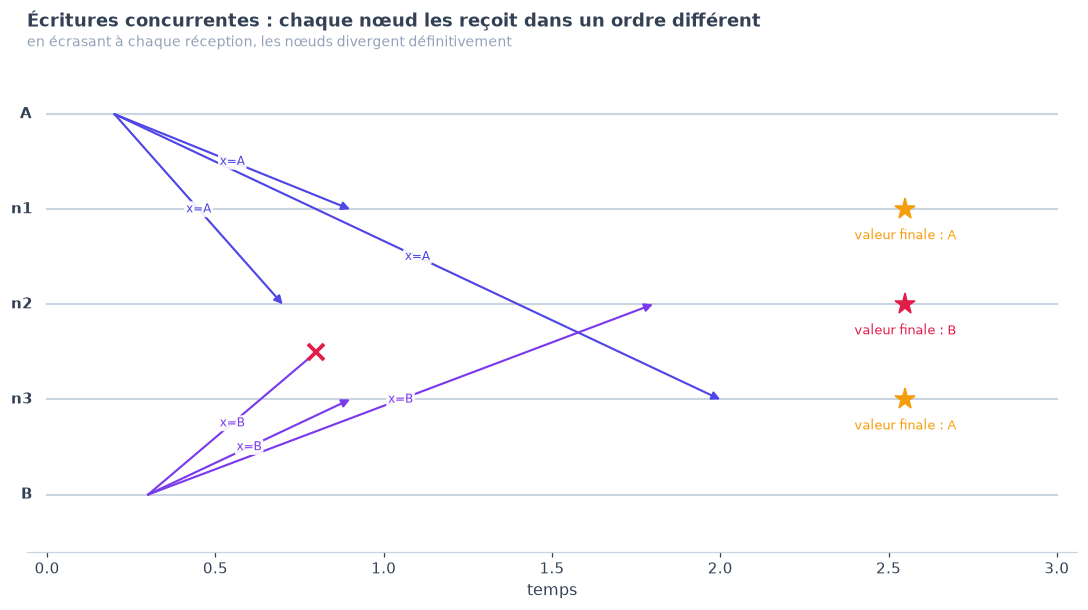

In [2]:
class Ecrase(Node):
    def __init__(self, name):
        super().__init__(name)
        self.x = None
    def on_message(self, src, msg):
        if msg[0] == "set":
            self.x = msg[1]
            self.record(f"x={msg[1]}")

def latence(rng, src, dst):
    table = {("A", "n2"): 0.5, ("B", "n2"): 1.5, ("A", "n3"): 1.8, ("B", "n3"): 0.6, ("A", "n1"): 0.7}
    return table.get((src, dst), 1.0)

net = Network(seed=0, latency=latence)
noeuds = {n: net.add(Ecrase(n)) for n in ("n1", "n2", "n3")}
A, B = net.add(Node("A")), net.add(Node("B"))
net.block("B", "n1")
for n in noeuds:
    net.at(0.2, A.send, n, ("set", "A"))
    net.at(0.3, B.send, n, ("set", "B"))
net.run()
st = SpaceTime(["A", "n1", "n2", "n3", "B"], t_max=3, width=10,
               title="Écritures concurrentes : chaque nœud les reçoit dans un ordre différent",
               subtitle="en écrasant à chaque réception, les nœuds divergent définitivement")
st.from_trace(net.trace, color_of=lambda d: INDIGO if d.src == "A" else VIOLET, label_of=lambda d: f"x={d.msg[1]}")
for n, node in noeuds.items():
    st.event(n, 2.55, f"valeur finale : {node.x}", kind="star", color=ROSE if node.x != "A" else AMBER)
st.show()

`n2` termine avec B, `n1` et `n3` avec A : la base n'est pas cohérente, même « à terme ».
Pour converger, il faut une règle de résolution (cours 3) : LWW (Cassandra), résolution
manuelle avec frères (Riak).

**LWW** (dernier écrivain gagnant) est le plus simple : chaque écriture porte un
horodatage, la plus grande gagne partout. Mais un horodatage ne dit pas si deux valeurs
sont **réellement concurrentes** ou **successives** : LWW écrase de la même façon une
valeur que l'écrivain avait vue (légitime) et une valeur qu'il ignorait (perte de
données). Pour résoudre les conflits proprement, il faut **détecter** la concurrence.

> **À retenir.** Faute d'ordre global, des répliques qui écrasent à chaque réception
> divergent. Converger exige une règle commune ; ne rien perdre exige de savoir quelles
> écritures sont concurrentes.

## 2. La relation « arrivé avant » (section *The "happens-before" relationship and concurrency*)

Une opération A **est arrivée avant** une opération B si B connaît A, en dépend, ou
s'appuie dessus d'une manière ou d'une autre. Exemple : un client insère une ligne, un
autre l'incrémente ; l'incrément s'appuie sur la valeur insérée, il est **causalement
dépendant** de l'insertion. Deux opérations sont **concurrentes** si aucune n'est arrivée
avant l'autre. Pour deux opérations, trois cas : A avant B, B avant A, ou concurrentes.
Si l'une précède l'autre, la plus récente peut écraser l'autre ; si elles sont
concurrentes, il y a un conflit à résoudre.

**Concurrence, temps et relativité** (encadré *Concurrency, Time, and Relativity*).
« Concurrent » ne veut pas dire « au même instant » : l'heure exacte est d'ailleurs
difficile à connaître dans un système distribué (chapitre 8). Deux opérations
sont concurrentes si **aucune n'a pu avoir connaissance de l'autre**. Le parallèle avec la
relativité restreinte est classique : deux événements trop éloignés pour qu'un signal
lumineux les relie ne peuvent pas s'influencer. Dans un réseau, c'est encore plus large :
si le réseau était lent ou coupé, deux opérations séparées de plusieurs secondes peuvent
être concurrentes.

On rend la relation calculable en attachant à chaque événement un **vecteur** : un
compteur par processus, incrémenté à chaque événement local, et fusionné (maximum
composante par composante) avec celui que porte un message reçu. Alors A est arrivé avant
B si et seulement si le vecteur de A est inférieur ou égal à celui de B composante par
composante (et différent) ; sinon, s'ils sont incomparables, A et B sont concurrents
(fonction `rp.vv_compare`). Calculons-le sur six événements de trois processus, dont deux
séparés de longtemps mais concurrents parce que le message entre eux s'est perdu.

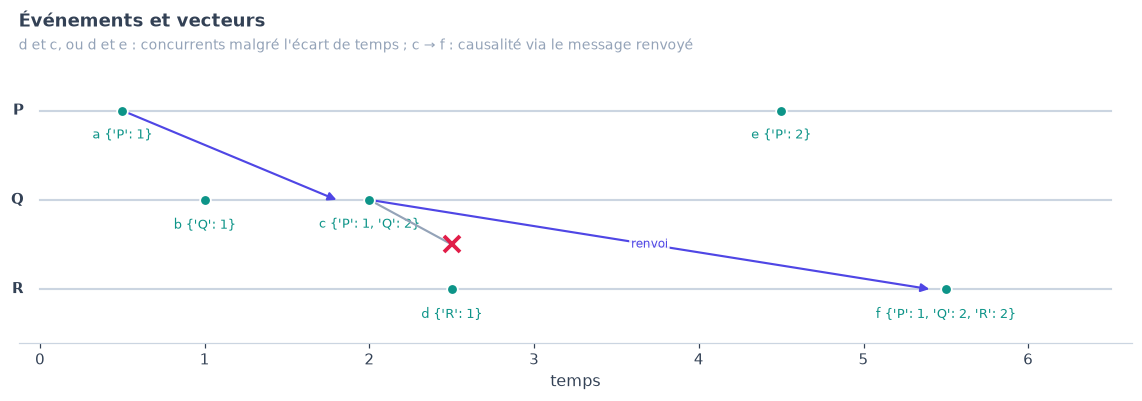

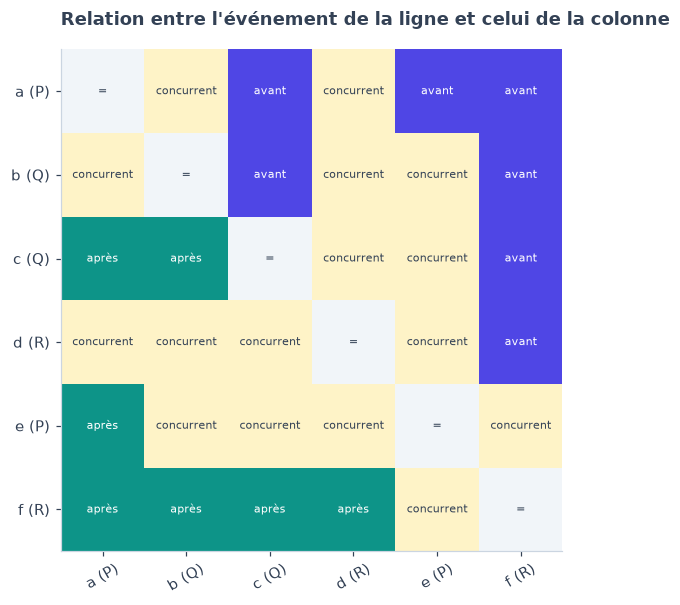

In [3]:
evts = {}
vp, vq, vr = {}, {}, {}
vp = rp.vv_increment(vp, "P"); evts["a (P)"] = (vp, "P", 0.5)
vq = rp.vv_increment(vq, "Q"); evts["b (Q)"] = (vq, "Q", 1.0)
m1 = dict(vp)                                     # P envoie à Q
vq = rp.vv_increment(rp.vv_merge(vq, m1), "Q"); evts["c (Q)"] = (vq, "Q", 2.0)
vr = rp.vv_increment(vr, "R"); evts["d (R)"] = (vr, "R", 2.5)     # le message de Q vers R est perdu
vp = rp.vv_increment(vp, "P"); evts["e (P)"] = (vp, "P", 4.5)
vr = rp.vv_increment(rp.vv_merge(vr, vq), "R"); evts["f (R)"] = (vr, "R", 5.5)   # Q renvoie, cette fois reçu

st = SpaceTime(["P", "Q", "R"], t_max=6.5, width=10.5, title="Événements et vecteurs",
               subtitle="d et c, ou d et e : concurrents malgré l'écart de temps ; c → f : causalité via le message renvoyé")
st.msg("P", 0.5, "Q", 1.8, "", color=INDIGO)
st.msg("Q", 2.0, "R", 3.0, "", color=GRAY, lost=True)
st.msg("Q", 2.0, "R", 5.4, "renvoi", color=INDIGO)
for name, (v, proc, t) in evts.items():
    st.event(proc, t, f"{name[0]} {dict(sorted(v.items()))}", kind="point", color=TEAL)
st.show()

names = list(evts)
code = {"avant": -1, "apres": 1, "concurrent": 0, "egal": 2}
Mx = np.array([[code[rp.vv_compare(evts[a][0], evts[b][0])] for b in names] for a in names])
fig, ax = plt.subplots(figsize=(8.5, 5.6))
from matplotlib.colors import ListedColormap
cmap = ListedColormap([INDIGO, LIGHT[AMBER], TEAL, "#F1F5F9"])
ax.imshow(Mx, cmap=cmap, vmin=-1.5, vmax=2.5)
lab = {-1: "avant", 1: "après", 0: "concurrent", 2: "="}
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, lab[Mx[i, j]], ha="center", va="center", fontsize=7.5,
                color="white" if Mx[i, j] in (-1, 1) else SLATE)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=30)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
ax.grid(False)
ax.set_title("Relation entre l'événement de la ligne et celui de la colonne")
plt.tight_layout(); plt.show()

Lecture du tableau : `a` précède `c` (par le message de P à Q) et donc `f` (par le
renvoi) ; `d` est concurrent de tout ce qui se passe sur P et Q avant le renvoi, y
compris `e`, survenu deux secondes plus tard : le message perdu a empêché R de savoir.
Le temps physique ne joue aucun rôle ; seule compte la circulation de l'information.

> **À retenir.** A est arrivé avant B si B a pu avoir connaissance de A ; sinon, ils sont
> concurrents, quel que soit l'écart de temps. Des vecteurs de compteurs rendent cette
> relation calculable.

## 3. Capturer la relation sur une réplique : le panier (section *Capturing the happens-before relationship*)

Commençons par une seule réplique. L'algorithme du livre :

- le serveur tient un **numéro de version** par clé, incrémenté à chaque écriture, et
  stocké avec la valeur ;
- une lecture renvoie **toutes** les valeurs non écrasées (les frères) et le numéro de
  version courant ; on doit lire avant d'écrire ;
- une écriture inclut le numéro de version de la lecture précédente et **fusionne** les
  frères lus ; la réponse renvoie à son tour les frères restants ;
- le serveur écrase les valeurs de version **inférieure ou égale** à celle fournie (elles
  ont été fusionnées) et garde celles de version **supérieure** (concurrentes).

Une écriture sans numéro de version est concurrente de toutes les autres : elle n'écrase
rien. Le serveur n'a pas besoin de comprendre les valeurs. Rejouons l'exemple du livre
(classe `rp.VersionedKeyServer`) : deux clients remplissent le même panier.

In [4]:
srv = rp.VersionedKeyServer()
etapes = []
def ecrit(client, valeur, version_lue):
    v, freres = srv.put(valeur, version_lue)
    etapes.append({"client": client, "écrit": valeur, "version lue": version_lue or "aucune",
                   "version attribuée": v, "frères après l'écriture": " | ".join(f"v{k}: {x}" for k, x in freres.items())})
    return v, freres

v1, f = ecrit("client 1", ["lait"], None)
v2, f2 = ecrit("client 2", ["oeufs"], None)
v3, f3 = ecrit("client 1", ["lait", "farine"], v1)
fusion2 = sorted(set().union(*map(set, f2.values()))) + ["jambon"]
v4, f4 = ecrit("client 2", ["oeufs", "lait", "jambon"], v2)
fusion1 = ["lait", "farine", "oeufs", "lard"]
v5, f5 = ecrit("client 1", fusion1, v3)
pd.DataFrame(etapes).set_index("client")

,écrit,version lue,version attribuée,frères après l'écriture
client,,,,
client 1,[lait],aucune,1,v1: ['lait']
client 2,[oeufs],aucune,2,v1: ['lait'] | v2: ['oeufs']
client 1,"[lait, farine]",1,3,"v2: ['oeufs'] | v3: ['lait', 'farine']"
client 2,"[oeufs, lait, jambon]",2,4,"v3: ['lait', 'farine'] | v4: ['oeufs', 'lait',..."
client 1,"[lait, farine, oeufs, lard]",3,5,"v4: ['oeufs', 'lait', 'jambon'] | v5: ['lait',..."


Pas à pas :

1. client 1 ajoute du lait : première écriture, version 1 ;
2. client 2 ajoute des œufs sans savoir que client 1 a mis du lait (pas de version) : le
   serveur garde les deux frères, version 2 ;
3. client 1, qui n'a vu que la version 1, envoie [lait, farine] avec la version 1 : elle
   remplace [lait] (version 1) mais pas [oeufs] (version 2, concurrente) ;
4. client 2 fusionne les deux frères qu'il avait reçus ([lait] et [oeufs]), ajoute du
   jambon, envoie avec la version 2 : remplace [oeufs], garde [lait, farine] ;
5. client 1 fusionne ce qu'il avait reçu ([lait, farine] et [oeufs]), ajoute du lard,
   envoie avec la version 3 : remplace [lait, farine], garde [oeufs, lait, jambon].

Les clients ne sont jamais tout à fait à jour, puisqu'une autre opération est toujours en
cours, mais les anciennes valeurs finissent écrasées et **aucune écriture n'est perdue**.
Le graphe des dépendances causales le montre :

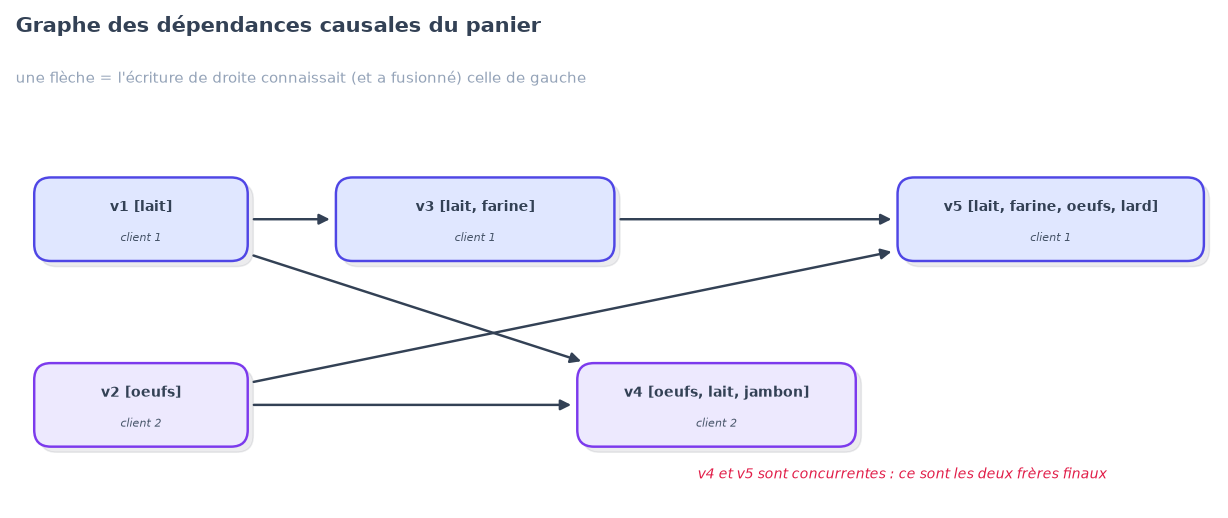

In [5]:
d = Diagram(13, 4.4, title="Graphe des dépendances causales du panier",
            subtitle="une flèche = l'écriture de droite connaissait (et a fusionné) celle de gauche")
pos = {1: (1.4, 3.1), 2: (1.4, 1.1), 3: (5.0, 3.1), 4: (7.6, 1.1), 5: (11.2, 3.1)}
txt = {1: ("v1 [lait]", "client 1"), 2: ("v2 [oeufs]", "client 2"), 3: ("v3 [lait, farine]", "client 1"),
       4: ("v4 [oeufs, lait, jambon]", "client 2"), 5: ("v5 [lait, farine, oeufs, lard]", "client 1")}
for k, (x, y) in pos.items():
    d.box(f"v{k}", x, y, txt[k][0], sub=txt[k][1], color=INDIGO if txt[k][1] == "client 1" else VIOLET,
          w=2.3 if k < 3 else 3.0 if k < 5 else 3.3, h=0.9, fontsize=9)
for a, b in [(1, 3), (1, 4), (2, 4), (3, 5), (2, 5)]:
    d.arrow(f"v{a}", f"v{b}", color=SLATE)
d.note(9.6, 0.35, "v4 et v5 sont concurrentes : ce sont les deux frères finaux", color=ROSE)
d.show()

> **À retenir.** Un numéro de version par clé, renvoyé par le client à chaque écriture,
> suffit au serveur pour distinguer ce que l'écriture remplace (versions ≤ la sienne) de
> ce qui lui est concurrent (versions supérieures), sans interpréter les valeurs.

## 4. Fusionner les frères (section *Merging concurrently written values*)

L'algorithme ne perd rien, mais il reporte la fusion sur le client. Pour un panier,
l'**union** des frères est une fusion raisonnable... sauf pour les suppressions : un
article retiré dans un frère réapparaît s'il est encore dans un autre (cours 3,
section 7). Il faut alors laisser une **pierre tombale** marquant la suppression, avec un
numéro de version, pour qu'elle survive à la fusion. Comme écrire ce code est fastidieux et propice aux erreurs, des structures comme les CRDT de Riak fusionnent automatiquement ensembles, compteurs ou dictionnaires.

**Et si les clients ne fusionnent pas ?** Une écriture « aveugle » (sans version) n'écrase
rien : elle ajoute un frère. Un client mal écrit qui n'envoie jamais de version fait
grossir indéfiniment la liste des frères. Simulons des clients qui, à chaque écriture,
omettent la version avec une probabilité $q$.

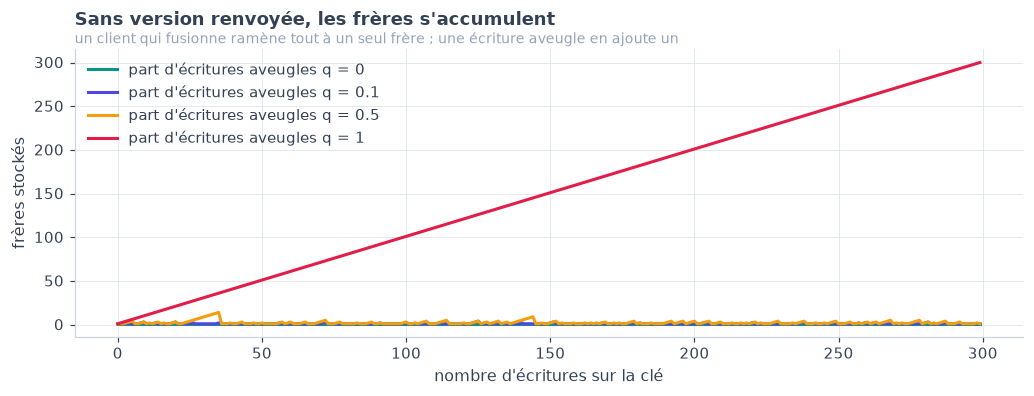

In [6]:
def freres_apres(n_ecritures, q, seed):
    rnd = random.Random(seed)
    s = rp.VersionedKeyServer()
    version, freres = s.get()
    tailles = []
    for i in range(n_ecritures):
        if rnd.random() < q:
            s.put([f"x{i}"], None)                    # écriture aveugle
        else:
            version, freres = s.get()
            s.put(sorted(set().union(*map(set, freres.values()), {f"x{i}"})), version)
        tailles.append(len(s.siblings))
    return tailles

fig, ax = plt.subplots(figsize=(9.5, 3.7))
for q, c in [(0.0, TEAL), (0.1, INDIGO), (0.5, AMBER), (1.0, ROSE)]:
    ax.plot(freres_apres(300, q, 1), color=c, label=f"part d'écritures aveugles q = {q:g}")
ax.set_xlabel("nombre d'écritures sur la clé"); ax.set_ylabel("frères stockés")
ax.set_title("Sans version renvoyée, les frères s'accumulent")
subtitle(ax, "un client qui fusionne ramène tout à un seul frère ; une écriture aveugle en ajoute un")
ax.legend()
plt.tight_layout(); plt.show()

Un client consciencieux ramène systématiquement la clé à un seul frère ; chaque écriture
aveugle en ajoute un, que seule une écriture correcte ultérieure éliminera. Avec $q = 1$,
la valeur grossit sans fin : c'est le problème d'**explosion des frères**, que Riak a dû
traiter. Le contrat est clair : **lire avant d'écrire, et renvoyer le contexte lu**.

> **À retenir.** Les frères préservent les écritures concurrentes, mais le client doit
> les fusionner (avec des pierres tombales pour les suppressions) et renvoyer la version
> lue, faute de quoi ils s'accumulent.